<a href="https://colab.research.google.com/github/Venkat-267-byte/Deep-Learning-/blob/main/Skill/Skill_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q ultralytics opencv-python matplotlib

import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import time
import json

from google.colab import files
from ultralytics import YOLO

# Load the model if it is not already loaded
try:
    model
    print("Existing YOLO model is being reused!")
except NameError:
    model = YOLO("yolov8n.pt")
    print("YOLOv8 model loaded successfully!")

print("GPU Available:", torch.cuda.is_available())


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLOv8 model loaded successfully!
GPU Available: False


In [2]:

def letterbox(image, size=640):

    height, width = image.shape[:2]

    # Calculate resizing ratio
    ratio = min(size / width, size / height)

    new_width = int(round(width * ratio))
    new_height = int(round(height * ratio))

    # Resize image
    resized = cv2.resize(
        image,
        (new_width, new_height)
    )

    # Calculate padding
    pad_width = size - new_width
    pad_height = size - new_height

    left = pad_width // 2
    right = pad_width - left

    top = pad_height // 2
    bottom = pad_height - top

    # Add padding
    output = cv2.copyMakeBorder(
        resized,
        top, bottom, left, right,
        cv2.BORDER_CONSTANT,
        value=(114, 114, 114)
    )

    return output, ratio, (left, top)

print("Letterbox preprocessing function created!")


Letterbox preprocessing function created!


In [3]:

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded!")

filename = next(iter(uploaded))
image_bytes = uploaded[filename]

if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
    raise ValueError("Please upload a valid image file.")

if len(image_bytes) == 0:
    raise ValueError("Uploaded file is empty.")

# Decode image bytes
image_array = np.frombuffer(image_bytes, np.uint8)
image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

if image is None:
    raise ValueError("Image decoding failed!")

print("Request validation successful!")
print("Filename:", filename)
print("Original image shape:", image.shape)
print("Image size:", len(image_bytes), "bytes")


Saving Screenshot 2026-11-11 104734.png to Screenshot 2026-11-11 104734.png
Request validation successful!
Filename: Screenshot 2026-11-11 104734.png
Original image shape: (338, 535, 3)
Image size: 371129 bytes


In [4]:

# Resize image using letterboxing
processed_image, ratio, padding = letterbox(image)

print("Original shape:", image.shape)
print("Preprocessed shape:", processed_image.shape)

# Convert BGR to RGB
rgb_image = cv2.cvtColor(
    processed_image,
    cv2.COLOR_BGR2RGB
)

# Convert image into PyTorch tensor
tensor = torch.from_numpy(
    rgb_image.transpose(2, 0, 1).copy()
)

# Convert to float and normalize
tensor = tensor.float() / 255.0

# Add batch dimension
tensor = tensor.unsqueeze(0)

# Move tensor to GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
tensor = tensor.to(device)

print("Tensor shape:", tensor.shape)
print("Tensor data type:", tensor.dtype)
print("Tensor device:", tensor.device)


Original shape: (338, 535, 3)
Preprocessed shape: (640, 640, 3)
Tensor shape: torch.Size([1, 3, 640, 640])
Tensor data type: torch.float32
Tensor device: cpu


In [5]:

# Run YOLO inference on the preprocessed image
start_time = time.perf_counter()

results = model.predict(
    source=processed_image,
    imgsz=640,
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu",
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

inference_time = time.perf_counter() - start_time

# Extract detection results
detections = []

for box in results[0].boxes:

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    coordinates = box.xyxy[0].tolist()

    detections.append({
        "object": model.names[class_id],
        "confidence": round(confidence * 100, 2),
        "bounding_box": [
            round(x, 2) for x in coordinates
        ]
    })

print("Model execution completed!")
print("Total detected objects:", len(detections))
print("Inference time:", round(inference_time, 4), "seconds")


Model execution completed!
Total detected objects: 11
Inference time: 7.7959 seconds


In [6]:

response = {
    "project": "VisionPort",
    "filename": filename,
    "device_used": "GPU" if torch.cuda.is_available() else "CPU",
    "input_shape": list(image.shape),
    "tensor_shape": list(tensor.shape),
    "total_objects": len(detections),
    "inference_time_seconds": round(inference_time, 4),
    "detections": detections
}

json_response = json.dumps(response, indent=4)

print("FINAL API RESPONSE")
print(json_response)


FINAL API RESPONSE
{
    "project": "VisionPort",
    "filename": "Screenshot 2026-11-11 104734.png",
    "device_used": "CPU",
    "input_shape": [
        338,
        535,
        3
    ],
    "tensor_shape": [
        1,
        3,
        640,
        640
    ],
    "total_objects": 11,
    "inference_time_seconds": 7.7959,
    "detections": [
        {
            "object": "cow",
            "confidence": 94.7,
            "bounding_box": [
                275.27,
                216.81,
                522.56,
                504.91
            ]
        },
        {
            "object": "person",
            "confidence": 82.12,
            "bounding_box": [
                375.78,
                165.89,
                433.04,
                258.2
            ]
        },
        {
            "object": "person",
            "confidence": 71.83,
            "bounding_box": [
                428.66,
                174.59,
                468.59,
                244.85
    

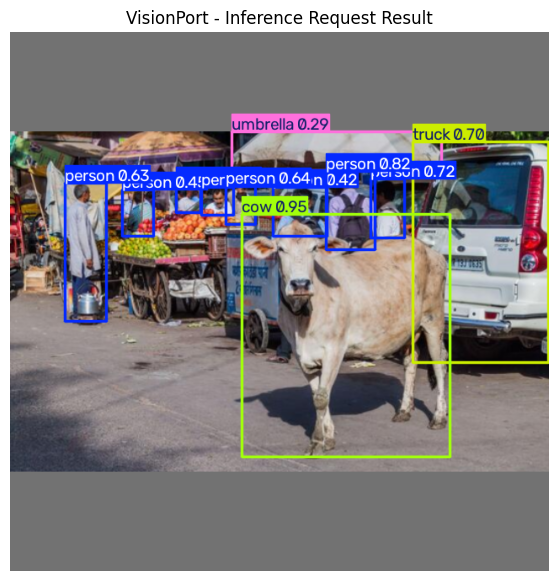

In [7]:

annotated_image = results[0].plot()

annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(annotated_image)
plt.title("VisionPort - Inference Request Result")
plt.axis("off")
plt.show()


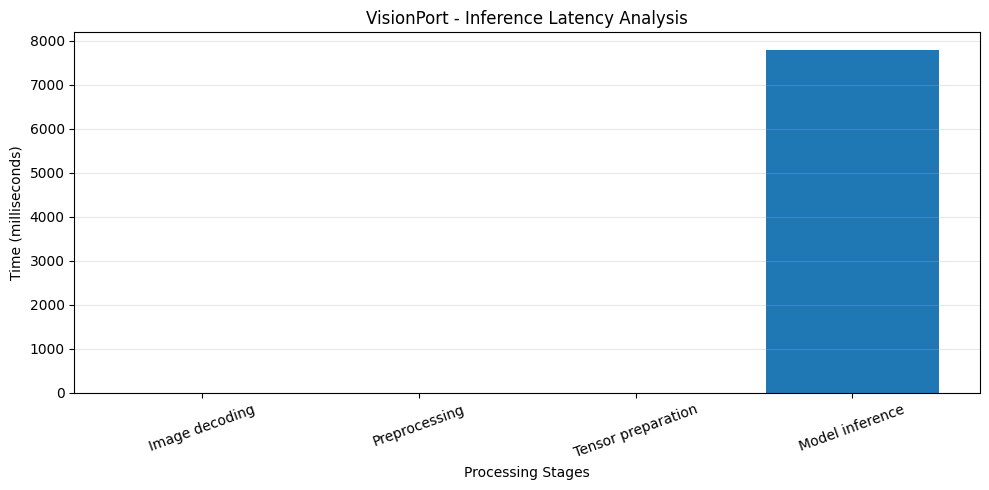

Latency in milliseconds:
Image decoding : 9.35 ms
Preprocessing : 1.11 ms
Tensor preparation : 4.92 ms
Model inference : 7795.93 ms


In [8]:

# Measure preprocessing and tensor preparation time
# separately for the latency demonstration.

start = time.perf_counter()
decoded_image = cv2.imdecode(
    np.frombuffer(image_bytes, np.uint8),
    cv2.IMREAD_COLOR
)
decode_time = time.perf_counter() - start

start = time.perf_counter()
processed_image, ratio, padding = letterbox(decoded_image)
preprocess_time = time.perf_counter() - start

start = time.perf_counter()
rgb = cv2.cvtColor(processed_image, cv2.COLOR_BGR2RGB)
prepared_tensor = torch.from_numpy(
    rgb.transpose(2, 0, 1).copy()
).float().div(255).unsqueeze(0)
tensor_time = time.perf_counter() - start

# Use the inference time recorded in Cell 5
stages = [
    "Image decoding",
    "Preprocessing",
    "Tensor preparation",
    "Model inference"
]

times = [
    decode_time * 1000,
    preprocess_time * 1000,
    tensor_time * 1000,
    inference_time * 1000
]

plt.figure(figsize=(10, 5))
plt.bar(stages, times)

plt.title("VisionPort - Inference Latency Analysis")
plt.xlabel("Processing Stages")
plt.ylabel("Time (milliseconds)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Latency in milliseconds:")
for stage, value in zip(stages, times):
    print(stage, ":", round(value, 2), "ms")
